In [3]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

data = pd.read_csv("../PrebolesII.csv", usecols=['elev', 'cloudsLow', 'cloudsMid', 'cloudsHigh', 'humidity', 'pressure',
                                               'irradiance', 'kind', 'actualArrebol'])
data['cloudm_cloudh'] = data['cloudsHigh']*data['cloudsMid']

x = data.drop("actualArrebol", axis=1)
y = data["actualArrebol"]

modelo = Pipeline([
    ('scaler', StandardScaler()),
    ("logistic", LogisticRegression(max_iter=7500))
])

# Entrenamiento final
modelo.fit(x, y)

def calcular_probabilidades(data_input):
    return modelo.predict_proba(data_input)[:, 1]




In [19]:
import numpy as np
np.random.seed(1)

data_test = pd.DataFrame({
    'elev': np.random.uniform(-6, 0, 1000),
    'cloudsLow': np.random.uniform(0, 101, 1000),      
    'cloudsMid': np.random.uniform(0, 101, 1000),
    'cloudsHigh': np.random.uniform(0, 101, 1000),     
    'humidity': np.random.uniform(10, 101, 1000),      
    'pressure': np.random.uniform(994, 1036, 1000),    
    'irradiance': np.random.uniform(0, 108, 1000),     
    'kind': np.random.randint(0, 2, 1000)
})
data_test['cloudm_cloudh'] = data_test['cloudsMid'] * data_test['cloudsHigh']
data_test.head()

,elev,cloudsLow,cloudsMid,cloudsHigh,humidity,pressure,irradiance,kind,cloudm_cloudh
0,-3.497868,32.906807,58.274762,80.141952,42.654989,1022.507730,71.017337,0,4670.253224
1,-1.678053,89.872561,88.414263,3.623794,69.491384,1026.096487,98.190405,0,320.395078
2,-5.999314,75.922480,61.465109,19.327247,61.559818,995.353519,97.410847,1,1187.951323
3,-4.186005,77.025842,25.417618,98.723012,13.103684,1035.255392,42.212343,0,2509.303807
4,-5.119465,47.417382,29.909122,97.040528,93.783195,997.835555,66.154263,0,2902.397015


In [20]:
probs = calcular_probabilidades(data_test)

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

n, bins, patches = plt.hist(calcular_probabilidades(calcular_probabilidades(data_test)), bins=20, color="#2E86AB", edgecolor="white", alpha=0.85)

for i, patch in enumerate(patches):
    patch.set_facecolor(plt.cm.viridis(n[i] / n.max()))

plt.xlabel("Probabilidades")
plt.ylabel("Frecuencia")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

c:\Users\sebat\Documents\10 trimestre\PROYECTO TITULO\preboles 2\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


ValueError: Expected 2D array, got 1D array instead:
array=[0.19282491 0.07476362 0.14550539 0.80985104 0.21793995 0.4407787
 0.02581879 0.90395002 0.33662228 0.42037064 0.06070982 0.15637564
 0.53447435 0.23603039 0.56314677 0.35536729 0.23003915 0.06782948
 0.71384397 0.61780172 0.35556876 0.04602343 0.20850393 0.23011089
 0.34113397 0.12941272 0.2017909  0.69334732 0.68577594 0.91409428
 0.82233509 0.04208832 0.10438964 0.25241802 0.31007587 0.30378343
 0.74564386 0.10919592 0.9499608  0.02875572 0.06056913 0.44337236
 0.62207611 0.00775784 0.83976237 0.76064864 0.04635118 0.66467745
 0.52509943 0.32305786 0.96971957 0.00628541 0.64081521 0.65395276
 0.44055977 0.56901008 0.07589439 0.17931377 0.23706258 0.34361878
 0.24592079 0.95850322 0.13311391 0.95005812 0.40605584 0.88031573
 0.11802565 0.66767052 0.03113324 0.89256755 0.86587032 0.23411822
 0.9051264  0.10429176 0.88809996 0.0932885  0.7910019  0.57364475
 0.15159647 0.60967742 0.37637005 0.53168814 0.70483976 0.41717195
 0.4

<Figure size 1000x600 with 0 Axes>

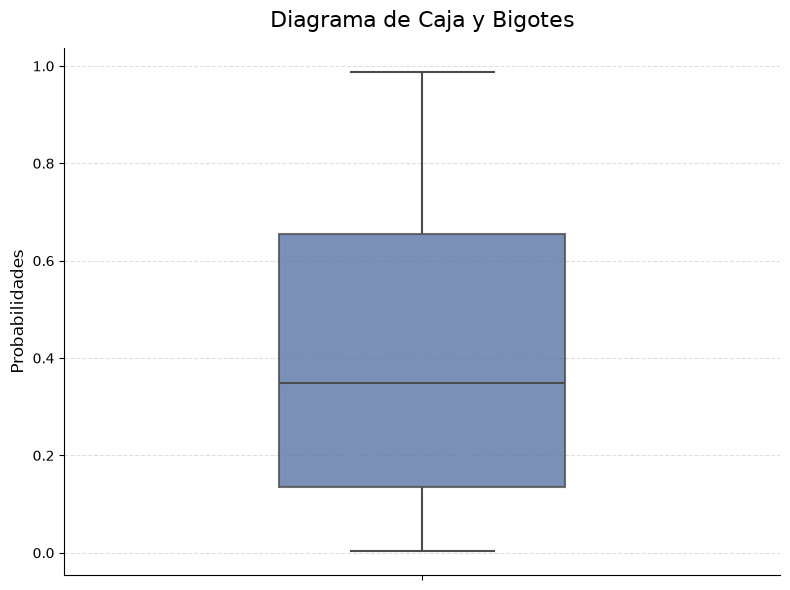

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.boxplot(
    y=calcular_probabilidades(data_test),
    color="#4C72B0",
    width=0.4,
    fliersize=5,
    linewidth=1.5,
    boxprops=dict(alpha=0.8)
)

plt.title("Diagrama de Caja y Bigotes", fontsize=16, pad=15)
plt.ylabel("Probabilidades", fontsize=12)
sns.despine(left=False)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [26]:
print(f"Mínima probabilidad: {min(probs):.3f}")
print(f"Máxima probabilidad: {max(probs):.3f}")

Mínima probabilidad: 0.003
Máxima probabilidad: 0.988
